# Linear and logistic victims

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import json
import pickle
import time
from dataclasses import replace

import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline

from config import EnvConfig, MethodConfig
from env import is_feasible
from fvi import StagedValue
from bdq import BranchQNet
from trpo import SwapPolicy
import experiment as ex             # training/evaluation shared with scripts/run_experiment.py

torch.set_num_threads(1)                # same thread count for every learner: comparable wall-clock
torch.set_flush_denormal(True)          # denormals in Adam state slow CPU math ~17x, unevenly across learners

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 11, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "0.85",
})

In [ ]:
QUICK = False

GAMMA_LINEAR = 2.95               
GAMMA_LOGISTIC = 2.0               
LAM_LINEAR = 1.0                  
LAM_LOGISTIC = 1.0
VICTIMS = {
    "linear":   EnvConfig(d=5, m=10, T=10, eta=0.2, theta_star_norm=GAMMA_LINEAR),
    "logistic": EnvConfig(d=5, m=10, T=10, eta=1.0, noise=0.0, task="logistic",
                          theta_star_norm=GAMMA_LOGISTIC),
    "mlp":      EnvConfig(d=5, m=10, T=10, eta=0.5, task="mlp", victim_hidden=8, victim_depth=1,
                          victim_act="tanh", target_steps=100),     # target: victim's SGD on flipped labels
}
LAM = {"linear": LAM_LINEAR, "logistic": LAM_LOGISTIC, "mlp": 0.1}
TASKS = list(VICTIMS)
RUN_VICTIMS = ["linear", "logistic"]  # add "mlp" to train the neural-net victim (needs its tuning in TUNED_FROM)                  
OVERWRITE = True
MYOPIC_PRIOR = False                  # True: TRPO/BDQ start from the batch-aware separable one-step score (ablation)
CFG = MethodConfig(weight_decay=1e-3, myopic_prior=MYOPIC_PRIOR)

N_SEEDS = 1 if QUICK else 10        
SEEDS = tuple(range(N_SEEDS))       
TRAIN_EPISODES = 1000 if QUICK else 2500   
TRPO_EPISODES = TRAIN_EPISODES            
assert TRAIN_EPISODES % CFG.N_episodes == 0 and TRPO_EPISODES % CFG.N_episodes == 0
TRPO_ACTOR = "alloc"                  # "alloc": exact allocation policy | "swap": the earlier swap policy
TUNED_FROM = Path("results/fair_tuning/selected.json")   # scripts/pick_best.py: equal grid, 8 configs x 2 seeds each
if TUNED_FROM.exists():
    TUNING = json.load(open(TUNED_FROM))["selected"]
    assert set(RUN_VICTIMS) <= set(TUNING), f"no tuned hyperparameters for {set(RUN_VICTIMS) - set(TUNING)} in {TUNED_FROM}"
    TUNED = [t for t in TASKS if t in TUNING]
    FEVI_HP = {t: TUNING[t]["fevi"]["hp"] for t in TUNED}
    TRPO_HP = {t: dict(TUNING[t]["trpo"]["hp"], trpo_actor=TRPO_ACTOR) for t in TUNED}
    BDQ_HP = {t: TUNING[t]["bdq"]["hp"] for t in TUNED}
    TRIALS = {t: {n: TUNING[t][n.lower()]["trials"] for n in ("FEVI", "TRPO", "BDQ")} for t in TUNED}
else:
    print(f"no {TUNED_FROM}: only the training cell needs it (results from Hyak load without it)")
EVAL_EPISODES, EVAL_SEED = 200, 999   
VAL_SEED = 998                       

RESULT_DIR = Path("results/victims")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

OURS = "FEVI"
LEARNERS = [OURS, "BDQ", "TRPO"]
NAMES = ["null", "greedy", *(["prior"] if MYOPIC_PRIOR else []), "TRPO", "BDQ", OURS]   # prior: untrained TRPO/BDQ
COLORS = {"null": "#5b5b5b", "greedy": "#eb6834", "TRPO": "#4a3aa7",
          "BDQ": "#e34948", OURS: "#2a78d6", "prior": "#c9a227"}
MARKERS = {"null": "D", "greedy": "s", "TRPO": "^", "BDQ": "X", OURS: "o", "prior": "v"}


def result_path(task):
    # one file per (task, m, T, gamma, lambda)
    return RESULT_DIR / ex.result_name(task, VICTIMS[task], LAM[task], MYOPIC_PRIOR,
                                       "_fair" + ("_quick" if QUICK else ""))


def learner_hp(task):
    # per-learner overrides of CFG
    return {OURS: FEVI_HP[task], "BDQ": BDQ_HP[task], "TRPO": dict(TRPO_HP[task], K_iters=n_iters("TRPO"))}


def n_iters(name):
    # updates = training episodes / episodes collected per update
    return (TRPO_EPISODES if name == "TRPO" else TRAIN_EPISODES) // CFG.N_episodes


def print_raw(title, rows, digits=3):
    n = len(next(iter(rows.values())))
    head = f"{title:26}{'mean':>10}{'std':>9}"
    if n > 1:
        head += "".join(f"{f'seed {s}':>10}" for s in SEEDS[:n])
    print("\n" + head)
    print("-" * len(head))
    for name, v in rows.items():
        v = np.asarray(v, dtype=float)
        line = f"{name:26}{v.mean():10.{digits}f}{v.std():9.{digits}f}"
        if n > 1:
            line += "".join(f"{x:10.{digits}f}" for x in v)
        print(line)

## Training

In [ ]:
def run_seed(task, s, K):
    cfg_k = replace(CFG, K_iters=K, lam=LAM[task])
    return ex.run_seed(VICTIMS[task], cfg_k, s, learner_hp(task), EVAL_EPISODES, EVAL_SEED, VAL_SEED,
                       LEARNERS)


In [7]:
for task in RUN_VICTIMS:
    path = result_path(task)
    if path.exists() and not OVERWRITE:
        print(f"{task}: {path} exists, skipping")
        continue
    runs = []
    for s in SEEDS:
        t0 = time.perf_counter()
        runs.append(run_seed(task, s, n_iters(OURS)))
        c = runs[-1]["costs"]
        print(f"[{task}] seed {s}: " + "  ".join(f"{n}={c[n]:.3f}" for n in NAMES)
              + f"  [{time.perf_counter() - t0:.0f}s]")
    with open(path, "wb") as f:
        pickle.dump({"ecfg": VICTIMS[task], "lam": LAM[task], "seeds": SEEDS,
                     "episodes": {n: n_iters(n) * CFG.N_episodes for n in LEARNERS},
                     "episodes_per_update": CFG.N_episodes,
                     "hp": {OURS: FEVI_HP[task], "TRPO": TRPO_HP[task], "BDQ": BDQ_HP[task]},
                     "trials": TRIALS[task], "cfg": replace(CFG, lam=LAM[task]),
                     "eval_episodes": EVAL_EPISODES, "runs": runs}, f)
    print(f"saved {path}")

[linear] seed 0: null=16.422  greedy=10.119  TRPO=6.831  BDQ=6.584  FEVI=5.979  [1373s]
[linear] seed 1: null=16.422  greedy=10.119  TRPO=6.896  BDQ=6.870  FEVI=6.003  [1357s]
[linear] seed 2: null=16.422  greedy=10.119  TRPO=6.870  BDQ=6.601  FEVI=5.993  [1352s]
[linear] seed 3: null=16.422  greedy=10.119  TRPO=6.789  BDQ=6.289  FEVI=5.996  [1368s]
[linear] seed 4: null=16.422  greedy=10.119  TRPO=7.357  BDQ=6.515  FEVI=6.002  [1359s]
[linear] seed 5: null=16.422  greedy=10.119  TRPO=6.851  BDQ=6.957  FEVI=5.987  [1357s]
[linear] seed 6: null=16.422  greedy=10.119  TRPO=6.765  BDQ=7.040  FEVI=5.968  [1358s]
[linear] seed 7: null=16.422  greedy=10.119  TRPO=6.920  BDQ=7.495  FEVI=5.993  [1359s]
[linear] seed 8: null=16.422  greedy=10.119  TRPO=6.740  BDQ=7.593  FEVI=5.996  [1368s]
[linear] seed 9: null=16.422  greedy=10.119  TRPO=6.835  BDQ=6.498  FEVI=5.976  [1364s]
saved results/victims/linear_m10_T10_gamma2.95_lam1.pkl
[logistic] seed 0: null=6.310  greedy=4.719  TRPO=3.779  BDQ=4.1

## Results

In [8]:
res = {}
for task in TASKS:
    if result_path(task).exists():
        with open(result_path(task), "rb") as f:
            res[task] = pickle.load(f)
    else:
        print(f"{task}: no results at {result_path(task)}")
SHOWN = [t for t in TASKS if t in res]
for t in SHOWN:
    print(f"{t:9} {len(res[t]['seeds'])} seeds, training episodes = {res[t]['episodes']}, {res[t]['ecfg']}")

linear    10 seeds, training episodes = {'FEVI': 2500, 'BDQ': 2500, 'TRPO': 2500}, EnvConfig(d=5, m=10, T=10, eta=0.2, noise=0.1, seed=0, theta_star_norm=2.95, dataset=None, dataset_n=10000, dataset_noise=0.0, dataset_pca=30, task='regression', victim_hidden=8, init_scale=0.3, target_scale=1.0, device='cpu')
logistic  10 seeds, training episodes = {'FEVI': 2500, 'BDQ': 2500, 'TRPO': 2500}, EnvConfig(d=5, m=10, T=10, eta=1.0, noise=0.0, seed=0, theta_star_norm=2.0, dataset=None, dataset_n=10000, dataset_noise=0.0, dataset_pca=30, task='logistic', victim_hidden=8, init_scale=0.3, target_scale=1.0, device='cpu')


### Episode cost

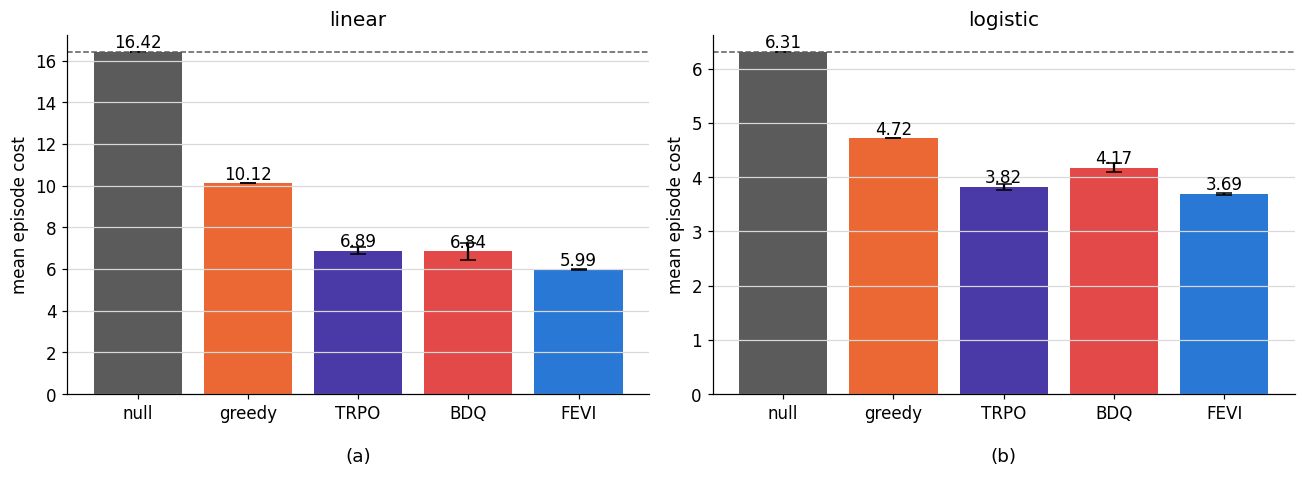


[linear] test cost              mean      std    seed 0    seed 1    seed 2    seed 3    seed 4    seed 5    seed 6    seed 7    seed 8    seed 9
-------------------------------------------------------------------------------------------------------------------------------------------------
null                          16.422    0.000    16.422    16.422    16.422    16.422    16.422    16.422    16.422    16.422    16.422    16.422
greedy                        10.119    0.000    10.119    10.119    10.119    10.119    10.119    10.119    10.119    10.119    10.119    10.119
TRPO                           6.885    0.166     6.831     6.896     6.870     6.789     7.357     6.851     6.765     6.920     6.740     6.835
BDQ                            6.844    0.412     6.584     6.870     6.601     6.289     6.515     6.957     7.040     7.495     7.593     6.498
FEVI                           5.989    0.011     5.979     6.003     5.993     5.996     6.002     5.987     5.968     5.9

In [9]:
def per_seed(t, key):
    return [r[key] for r in res[t]["runs"]]

fig, axes = plt.subplots(1, len(SHOWN), figsize=(6 * len(SHOWN), 4.5), squeeze=False)
for k, (ax, t) in enumerate(zip(axes[0], SHOWN)):
    C = {n: np.array([c[n] for c in per_seed(t, "costs")]) for n in NAMES}
    mu = [C[n].mean() for n in NAMES]
    ax.bar(NAMES, mu, yerr=[C[n].std() for n in NAMES], capsize=5,
           color=[COLORS[n] for n in NAMES])
    for i, v in enumerate(mu):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.axhline(C["null"].mean(), color=COLORS["null"], ls="--", lw=1)
    ax.set_title(t)
    ax.set_ylabel("mean episode cost")
    ax.text(0.5, -0.15, f"({'abc'[k]})", transform=ax.transAxes, ha="center", va="top",
            fontsize=12)
plt.tight_layout()
plt.show()

for t in SHOWN:
    print_raw(f"[{t}] test cost", {n: [c[n] for c in per_seed(t, "costs")] for n in NAMES})

### Paired comparison against greedy

In [ ]:
def boot_ci(D, n_boot=2000, seed=0):
    # mean and 95% CI, resampling training seeds and test episodes
    g, (S, E) = np.random.default_rng(seed), D.shape
    m = [D[g.integers(0, S, S)][:, g.integers(0, E, E)].mean() for _ in range(n_boot)]
    return D.mean(), *np.percentile(m, [2.5, 97.5])


def episode_costs(t, n):
    return np.array([p[n]["ep"] for p in per_seed(t, "profile")])        # (seeds, test episodes)


for t in SHOWN:
    G = episode_costs(t, "greedy")                                       # same test episodes for all: paired
    head = f"{'[' + t + '] test cost':22}{'mean':>9}{'95% CI':>18}{'- greedy':>11}{'95% CI':>18}"
    print("\n" + head + "\n" + "-" * len(head))
    for n in NAMES:
        X = episode_costs(t, n)
        m, lo, hi = boot_ci(X)
        dm, dlo, dhi = boot_ci(X - G)
        print(f"{n:22}{m:9.3f}  [{lo:6.3f}, {hi:6.3f}]{dm:+11.3f}  [{dlo:+6.3f}, {dhi:+6.3f}]")


### Budget ledger

In [ ]:
def budget(t):
    # per-learner budget; per-iteration optimizer updates are fixed by the training loops
    r, cfg, E = res[t], res[t]["cfg"], res[t]["eval_episodes"]
    K, T = r["episodes"][OURS] // r["episodes_per_update"], r["ecfg"].T
    f, b, p = (replace(cfg, **r["hp"][n]) for n in (OURS, "BDQ", "TRPO"))
    extra = int(cfg.myopic_prior)                 # TRPO/BDQ also score the untrained prior as a checkpoint
    return {
        OURS: dict(val=K * E, sim=K * T * cfg.N_episodes * f.fevi_M, step=T * f.fevi_fit_steps,
                   batch=min(cfg.batch_size, cfg.N_episodes)),
        "BDQ": dict(val=(K + extra) * E, sim=0, step=b.n_grad_steps, batch=b.batch_size),
        "TRPO": dict(val=(K + extra) * E, sim=0, step=1 + p.trpo_vf_iters, batch=p.trpo_minibatch),
    }


COLS = ["train eps", "val eps", "model trans.", "updates", "batch", "train s", "total s", "params",
        "tuning runs"]
for t in SHOWN:
    r, B = res[t], budget(t)
    K = r["episodes"][OURS] // r["episodes_per_update"]
    head = f"{'[' + t + ']':10}" + "".join(f"{c:>13}" for c in COLS)
    print("\n" + head + "\n" + "-" * len(head))
    for n in LEARNERS:
        row = [r["episodes"][n], B[n]["val"], B[n]["sim"], K * B[n]["step"], B[n]["batch"],
               np.mean([lg[n]["time"][-1] for lg in per_seed(t, "logs")]),
               np.mean([tm[n] for tm in per_seed(t, "times")]),
               r["runs"][0]["params"][n], r["trials"][n]]
        print(f"{n:10}" + "".join(f"{v:13,.0f}" for v in row))
print("\nupdates: optimizer updates over all networks (TRPO: natural-gradient + critic steps); "
      "train s excludes validation; model trans.: transitions FEVI simulates through the known victim")


### Cost over an evaluation episode

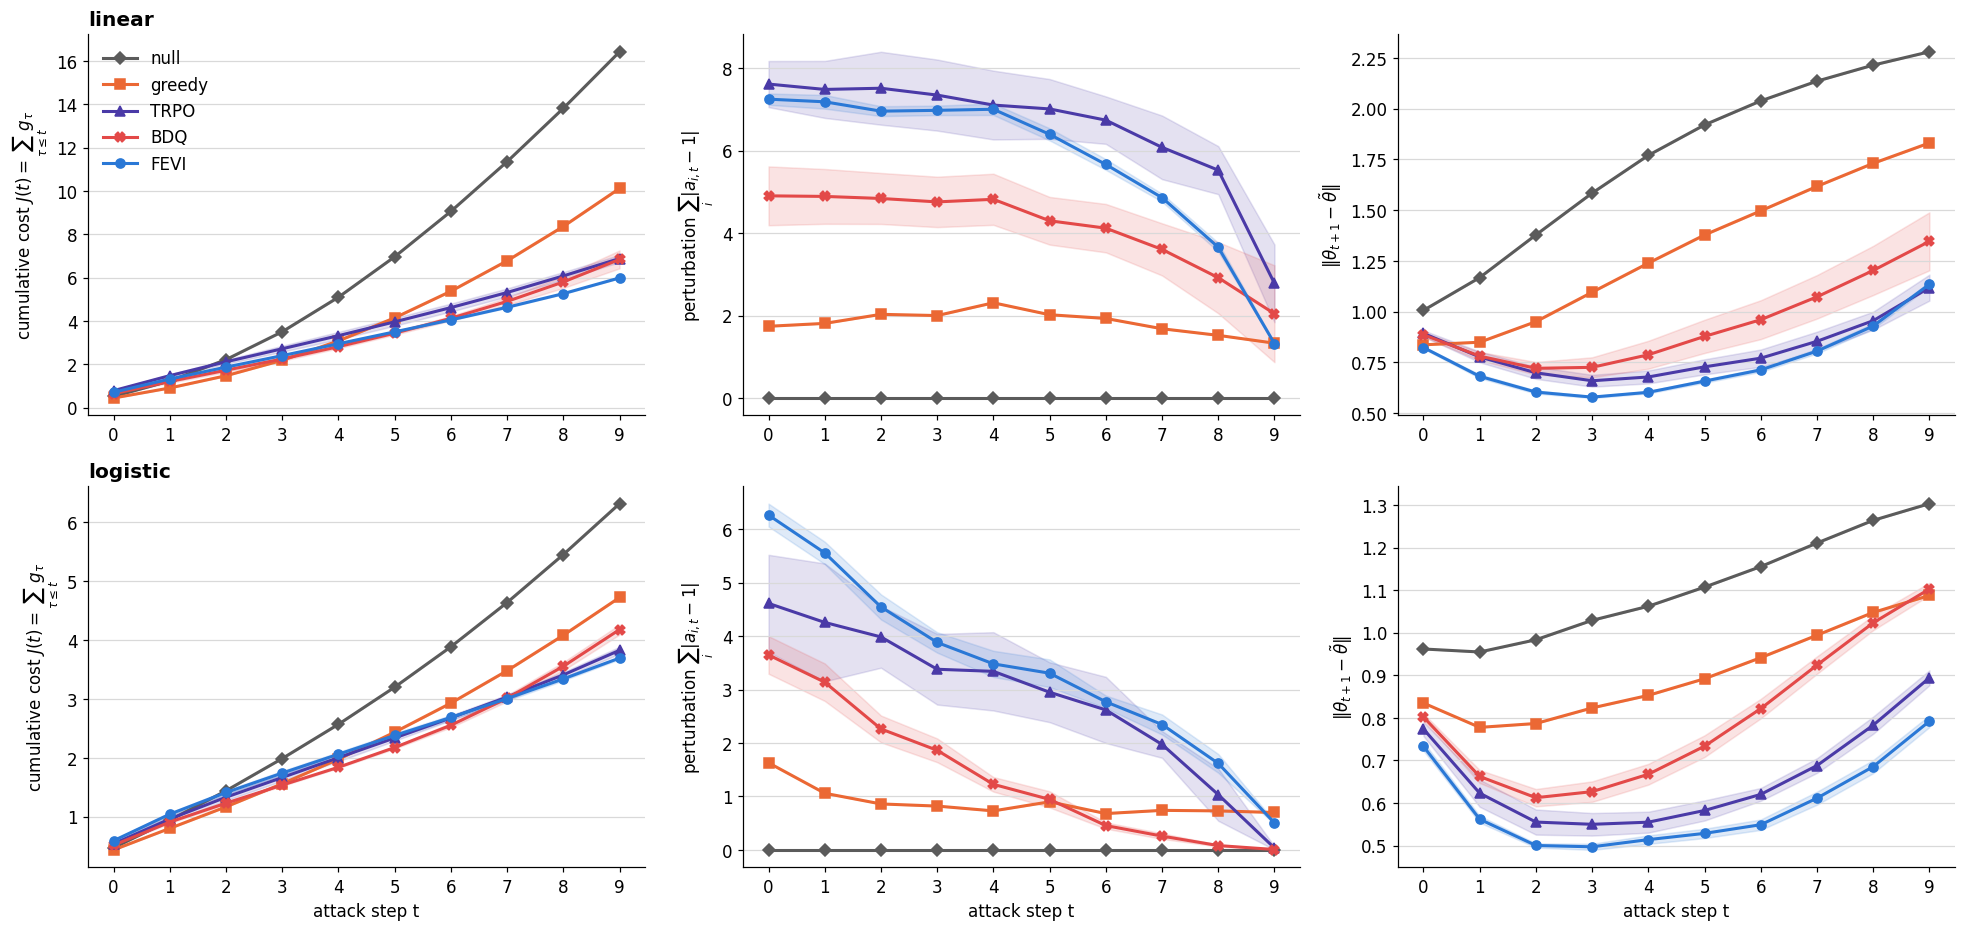


[linear] J(t)          t=0     t=1     t=2     t=3     t=4     t=5     t=6     t=7     t=8     t=9
null              0.52    1.24    2.22    3.51    5.10    6.97    9.06   11.35   13.82   16.42
greedy            0.45    0.91    1.48    2.19    3.09    4.15    5.38    6.78    8.37   10.12
TRPO              0.79    1.48    2.12    2.72    3.33    3.96    4.62    5.32    6.08    6.89
BDQ               0.65    1.21    1.73    2.25    2.82    3.44    4.13    4.91    5.80    6.84
FEVI              0.72    1.33    1.88    2.41    2.95    3.50    4.05    4.64    5.26    5.99

[logistic] J(t)          t=0     t=1     t=2     t=3     t=4     t=5     t=6     t=7     t=8     t=9
null              0.47    0.94    1.44    1.99    2.57    3.20    3.88    4.63    5.45    6.31
greedy            0.44    0.80    1.17    1.56    1.98    2.43    2.93    3.48    4.08    4.72
TRPO              0.54    0.96    1.33    1.67    2.00    2.34    2.68    3.03    3.41    3.82
BDQ               0.52    0.91    1.23

In [10]:
STEP_PANELS = [("cum", r"cumulative cost $J(t) = \sum_{\tau \leq t} g_\tau$"),
               ("pert", r"perturbation $\sum_i |a_{i,t} - 1|$"),
               ("gap", r"$\|\theta_{t+1} - \tilde{\theta}\|$")]

fig, axes = plt.subplots(len(SHOWN), 3, figsize=(18, 4.3 * len(SHOWN)), squeeze=False)
for row, t in enumerate(SHOWN):
    steps = np.arange(res[t]["ecfg"].T)
    for col, (key, ylabel) in enumerate(STEP_PANELS):
        ax = axes[row, col]
        for n in NAMES:
            P = np.array([p[n][key] for p in per_seed(t, "profile")])
            mu, sd = P.mean(0), P.std(0)
            ax.plot(steps, mu, f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n)
            ax.fill_between(steps, mu - sd, mu + sd, color=COLORS[n], alpha=0.15)
        ax.set_ylabel(ylabel)
        ax.set_xticks(steps)
        if row == len(SHOWN) - 1:
            ax.set_xlabel("attack step t")
    axes[row, 0].set_title(t, loc="left", fontweight="bold")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

for t in SHOWN:
    steps = np.arange(res[t]["ecfg"].T)
    print(f"\n[{t}] J(t){'':5}" + "".join(f"{f't={s}':>8}" for s in steps))
    for n in NAMES:
        J = np.mean([p[n]["cum"] for p in per_seed(t, "profile")], axis=0)
        print(f"{n:14}" + "".join(f"{v:8.2f}" for v in J))

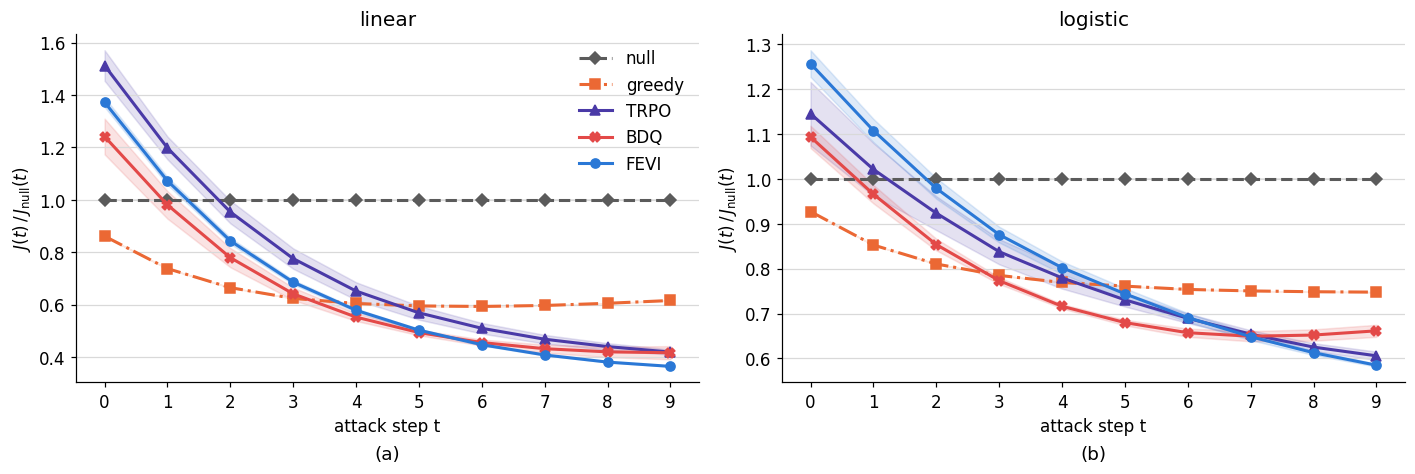


[linear] vs_null        t=0     t=1     t=2     t=3     t=4     t=5     t=6     t=7     t=8     t=9
null             1.000   1.000   1.000   1.000   1.000   1.000   1.000   1.000   1.000   1.000
greedy           0.861   0.738   0.665   0.624   0.605   0.595   0.593   0.597   0.605   0.616
TRPO             1.513   1.198   0.954   0.776   0.652   0.569   0.510   0.468   0.440   0.419
BDQ              1.242   0.981   0.780   0.642   0.553   0.494   0.456   0.432   0.420   0.417
FEVI             1.373   1.073   0.844   0.686   0.579   0.503   0.447   0.408   0.381   0.365

[logistic] vs_null        t=0     t=1     t=2     t=3     t=4     t=5     t=6     t=7     t=8     t=9
null             1.000   1.000   1.000   1.000   1.000   1.000   1.000   1.000   1.000   1.000
greedy           0.927   0.853   0.811   0.785   0.769   0.761   0.754   0.751   0.749   0.748
TRPO             1.146   1.022   0.924   0.838   0.780   0.731   0.689   0.654   0.625   0.606
BDQ              1.094   0.966   0.8

In [14]:
MODE = "vs_null"   # "raw" | "vs_null": J(t) / J_null(t) | "vs_greedy": J(t) - J_greedy(t)
YLABEL = {"raw": r"cumulative cost $J(t) = \sum_{\tau \leq t} g_\tau$",
          "vs_null": r"$J(t)\,/\,J_{\mathrm{null}}(t)$",
          "vs_greedy": r"$J(t) - J_{\mathrm{greedy}}(t)$"}
STYLES = {"null": "--", "greedy": "-.", "prior": ":", "TRPO": "-", "BDQ": "-", OURS: "-"}


def relative(J, n):
    if MODE == "vs_null":
        return J[n] / J["null"]
    if MODE == "vs_greedy":
        return J[n] - J["greedy"]
    return J[n]


fig, axes = plt.subplots(1, len(SHOWN), figsize=(6.5 * len(SHOWN), 4.5), squeeze=False)
for k, (ax, t) in enumerate(zip(axes[0], SHOWN)):
    steps = np.arange(res[t]["ecfg"].T)
    J = {n: np.array([p[n]["cum"] for p in per_seed(t, "profile")]) for n in NAMES}   # (seeds, T)
    for n in NAMES:
        Y = relative(J, n)
        mu, sd = Y.mean(0), Y.std(0)
        ax.plot(steps, mu, STYLES[n], marker=MARKERS[n], color=COLORS[n], lw=2, ms=6, label=n)
        ax.fill_between(steps, mu - sd, mu + sd, color=COLORS[n], alpha=0.15)
    if MODE == "vs_greedy":
        ax.axhline(0, color="k", lw=0.8)
    ax.set_title(t)
    ax.set_xlabel("attack step t")
    ax.set_xticks(steps)
    ax.set_ylabel(YLABEL[MODE])
    ax.text(0.5, -0.18, f"({'abc'[k]})", transform=ax.transAxes, ha="center", va="top", fontsize=12)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

for t in SHOWN:
    steps = np.arange(res[t]["ecfg"].T)
    J = {n: np.array([p[n]["cum"] for p in per_seed(t, "profile")]) for n in NAMES}
    print(f"\n[{t}] {MODE}{'':3}" + "".join(f"{f't={s}':>8}" for s in steps))
    for n in NAMES:
        print(f"{n:14}" + "".join(f"{v:8.3f}" for v in relative(J, n).mean(0)))

### Learning curves

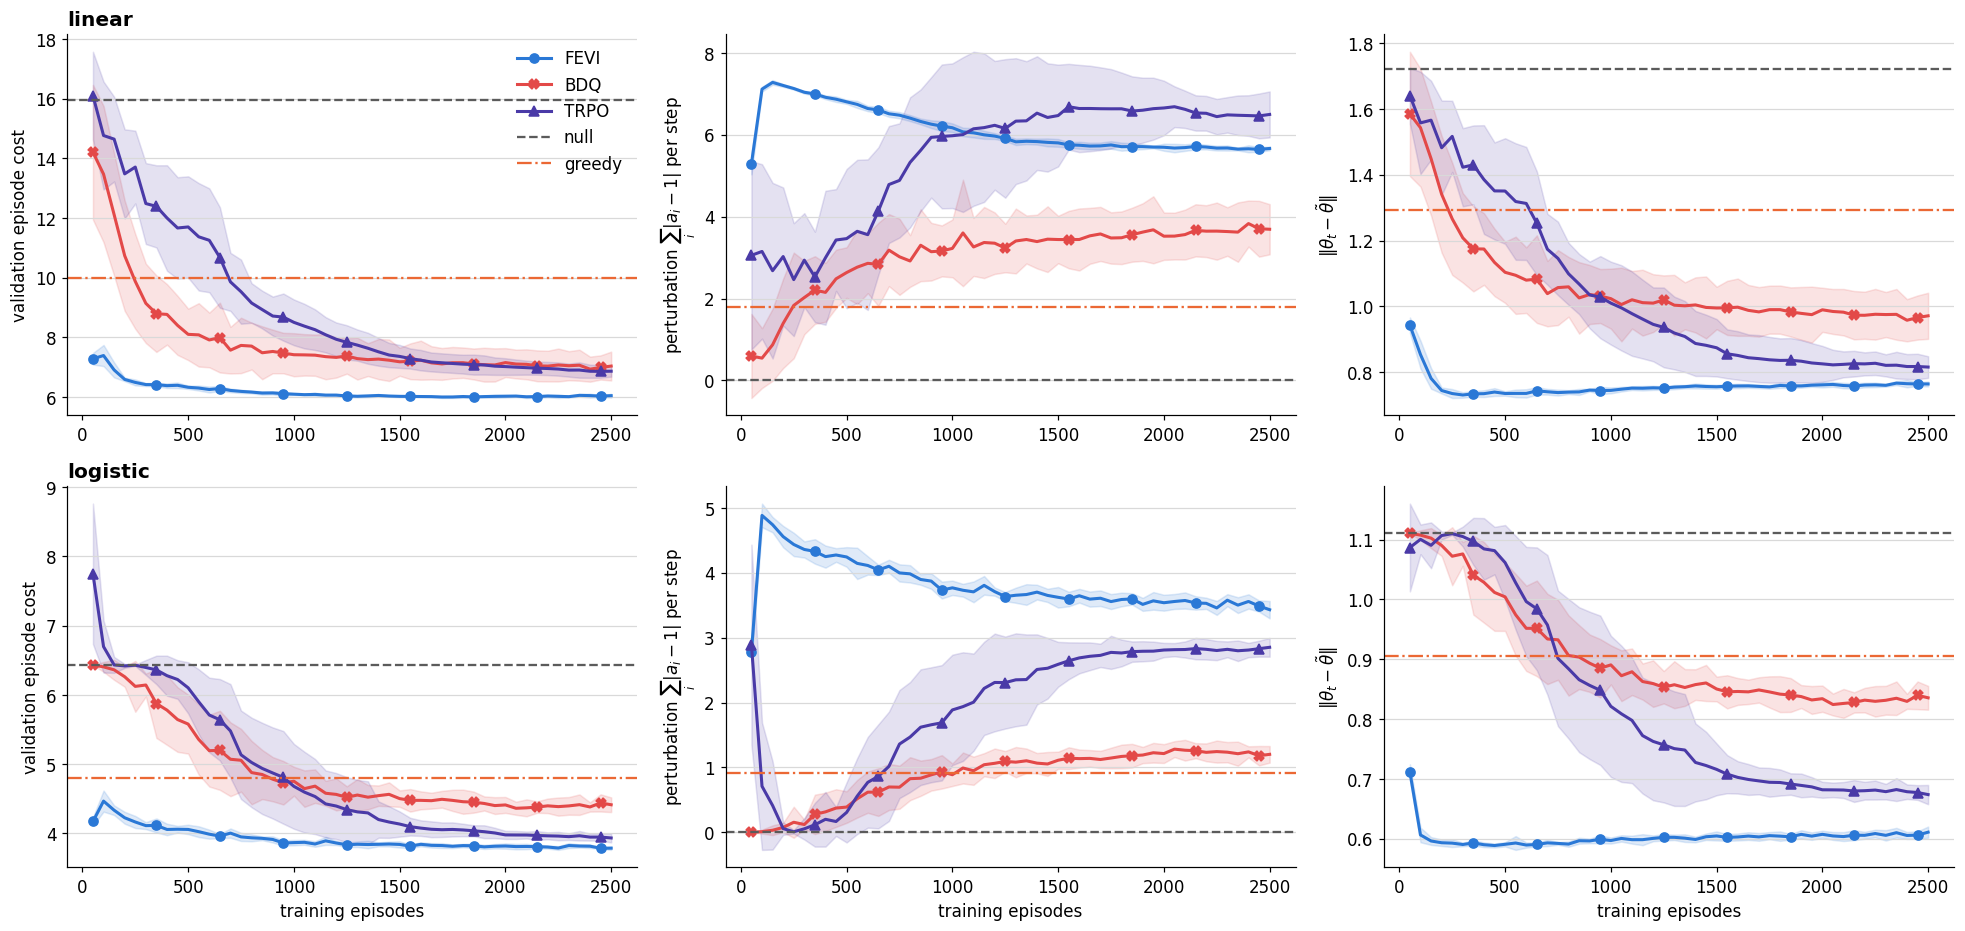


[linear] val. cost, last iter      mean      std    seed 0    seed 1    seed 2    seed 3    seed 4    seed 5    seed 6    seed 7    seed 8    seed 9
----------------------------------------------------------------------------------------------------------------------------------------------------
FEVI                           6.048    0.063     5.937     6.096     6.036     6.103     6.028     6.076     6.029     6.077     5.951     6.148
BDQ                            7.039    0.483     6.695     7.304     6.797     6.365     6.540     7.567     7.166     7.834     7.538     6.589
TRPO                           6.868    0.183     6.798     6.991     6.765     6.819     7.368     6.799     6.735     6.881     6.713     6.806

[logistic] val. cost, last iter      mean      std    seed 0    seed 1    seed 2    seed 3    seed 4    seed 5    seed 6    seed 7    seed 8    seed 9
---------------------------------------------------------------------------------------------------------------

In [11]:
PANELS = [("cost", "validation episode cost"),
          ("pert", r"perturbation $\sum_i |a_i - 1|$ per step"),
          ("gap", r"$\|\theta_t - \tilde{\theta}\|$")]


def curve_stats(t, name, key):
    H = np.array([lg[name][key] for lg in per_seed(t, "logs")])
    return H.mean(0), H.std(0)


fig, axes = plt.subplots(len(SHOWN), 3, figsize=(18, 4.3 * len(SHOWN)), squeeze=False)
for row, t in enumerate(SHOWN):
    ref = {n: np.mean([r[n] for r in per_seed(t, "ref")], axis=0) for n in ["null", "greedy"]}
    for col, (key, ylabel) in enumerate(PANELS):
        ax = axes[row, col]
        for n in LEARNERS:
            mu, sd = curve_stats(t, n, key)
            x = np.arange(1, len(mu) + 1) * res[t]["episodes_per_update"]
            ax.plot(x, mu, f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n,
                    markevery=max(1, len(x) // 8))
            ax.fill_between(x, mu - sd, mu + sd, color=COLORS[n], alpha=0.15)
        ax.axhline(ref["null"][col], color=COLORS["null"], ls="--", lw=1.5, label="null")
        ax.axhline(ref["greedy"][col], color=COLORS["greedy"], ls="-.", lw=1.5,
                   label="greedy")
        ax.set_ylabel(ylabel)
        if row == len(SHOWN) - 1:
            ax.set_xlabel("training episodes")
    axes[row, 0].set_title(t, loc="left", fontweight="bold")
axes[0, 0].legend(loc="upper right")
plt.tight_layout()
plt.show()

for t in SHOWN:
    print_raw(f"[{t}] val. cost, last iter",
              {n: [h[n][-1] for h in per_seed(t, "hist")] for n in LEARNERS})

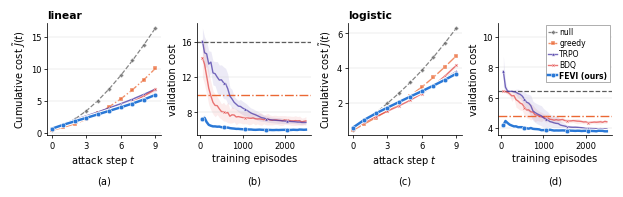

In [36]:
from matplotlib.ticker import MaxNLocator

PAPER_WIDTH = 5.5                      # ICLR \textwidth in inches: draw at print size, no rescaling
PAPER_RC = {"font.size": 6.5, "axes.labelsize": 6.5, "axes.titlesize": 7, "xtick.labelsize": 5.5,
            "ytick.labelsize": 5.5, "legend.fontsize": 6, "axes.linewidth": 0.5,
            "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2,
            "ytick.major.size": 2, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5,
            "axes.labelpad": 2, "grid.linewidth": 0.3, "pdf.fonttype": 42}
LINE = {"null": dict(ls="--", lw=0.8), "greedy": dict(ls="-.", lw=0.9),
        "TRPO": dict(ls="-", lw=0.9), "BDQ": dict(ls="-", lw=0.9), OURS: dict(ls="-", lw=1.6)}
PAPER_NAMES = [n for n in NAMES if n != "prior"]


def style(n, **kw):
    # ours: thicker and on top; the others slightly faded
    ours = n == OURS
    return dict(color=COLORS[n], marker=MARKERS[n], ms=3.0 if ours else 2.2, mec="white", mew=0.3,
                zorder=4 if ours else (3 if n in LEARNERS else 2), alpha=1.0 if ours else 0.75,
                **LINE[n], **kw)


def line(ax, x, y, n, **kw):
    # ours gets a thin white underlay, so it stays visible where lines cross
    if n == OURS:
        ax.plot(x, y, color="white", lw=LINE[n]["lw"] + 1.4, zorder=3.9, solid_capstyle="round")
    return ax.plot(x, y, **style(n, **kw))


def band(n):
    return dict(color=COLORS[n], alpha=0.22 if n == OURS else 0.1, lw=0)


def plot_cumulative(ax, t):
    # cumulative test cost J(t) per attack step
    steps = np.arange(res[t]["ecfg"].T)
    for n in PAPER_NAMES:
        P = np.array([p[n]["cum"] for p in per_seed(t, "profile")])
        mu, sd = P.mean(0), P.std(0)
        line(ax, steps, mu, n, label=n)
        ax.fill_between(steps, mu - sd, mu + sd, **band(n))
    ax.set_xlabel("attack step $t$")
    ax.set_xticks(steps[::3])
    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.set_ylabel("Cumulative cost $\\widetilde{J}(t)$")


def plot_validation(ax, t):
    # validation episode cost after each update, with null / greedy as reference lines
    ref = {n: np.mean([r[n] for r in per_seed(t, "ref")], axis=0)[0] for n in ["null", "greedy"]}
    for n in ["null", "greedy"]:
        ax.axhline(ref[n], color=COLORS[n], zorder=2, **LINE[n])
    for n in LEARNERS:
        H = np.array([lg[n]["cost"] for lg in per_seed(t, "logs")])
        mu, sd = H.mean(0), H.std(0)
        x = np.arange(1, len(mu) + 1) * res[t]["episodes_per_update"]
        line(ax, x, mu, n, markevery=max(1, len(x) // 5))
        ax.fill_between(x, mu - sd, mu + sd, **band(n))
    ax.set_xlabel("training episodes")
    ax.set_xticks([0, 1000, 2000])
    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.set_ylabel("validation cost")


with plt.rc_context(PAPER_RC):
    fig, axes = plt.subplots(1, 2 * len(SHOWN), figsize=(PAPER_WIDTH, 1.75))
    for row, t in enumerate(SHOWN):
        plot_cumulative(axes[2 * row], t)
        plot_validation(axes[2 * row + 1], t)
        axes[2 * row].set_title(t, loc="left", fontweight="bold", pad=3)
    for k, ax in enumerate(axes):
        ax.text(0.5, -0.36, f"({'abcdefgh'[k]})", transform=ax.transAxes, ha="center", va="top")
    handles, labels = axes[0].get_legend_handles_labels()
    labels = [f"{l} (ours)" if l == OURS else l for l in labels]
    lo, hi = axes[-1].get_ylim()
    axes[-1].set_ylim(lo, hi + 0.35 * (hi - lo))                   # headroom: legend above the null line
    leg = axes[-1].legend(handles, labels, loc="upper right", handlelength=1.2, handletextpad=0.3,
                          borderpad=0.3, labelspacing=0.25, borderaxespad=0.3,
                          frameon=True, fancybox=False, edgecolor="0.6", framealpha=1.0,
                          prop={"size": 5})
    leg.get_frame().set_linewidth(0.5)
    for text in leg.get_texts():
        if text.get_text().endswith("(ours)"):
            text.set_fontweight("bold")
    fig.tight_layout(pad=0.2, w_pad=0.6)
    os.makedirs("figures", exist_ok=True)
    fig.savefig("figures/cumulative_and_validation.pdf", bbox_inches="tight")
    plt.show()


### Wall-clock time

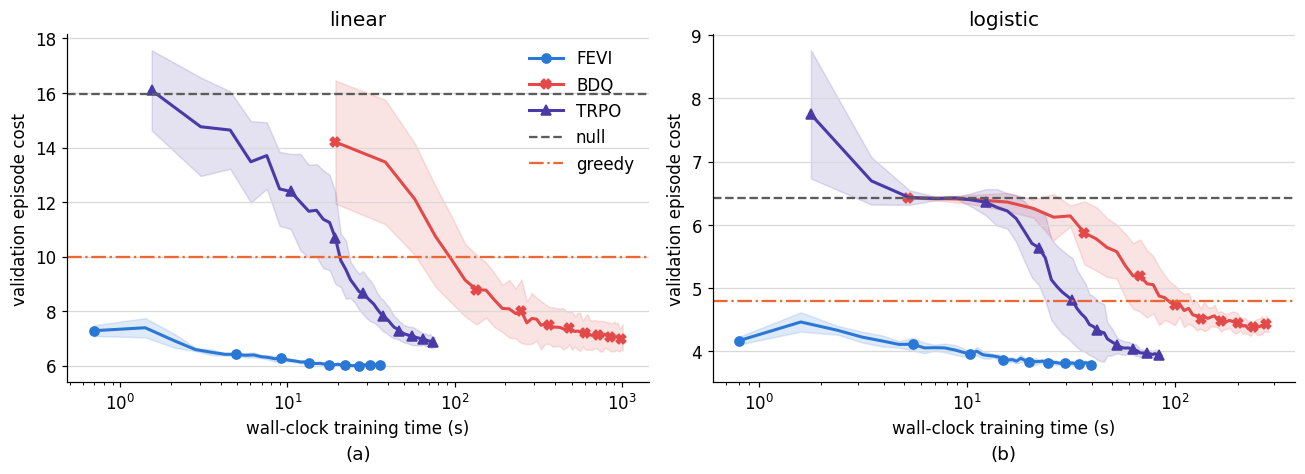


[linear] training time (s)      mean      std    seed 0    seed 1    seed 2    seed 3    seed 4    seed 5    seed 6    seed 7    seed 8    seed 9
-------------------------------------------------------------------------------------------------------------------------------------------------
FEVI                           114.6      0.7     113.0     115.2     114.7     114.0     115.5     114.6     114.5     115.4     114.7     114.8
BDQ                           1097.1      6.0    1107.5    1090.4    1089.6    1104.1    1095.1    1092.0    1093.1    1095.3    1103.3    1101.0
TRPO                           123.8      1.3     126.1     125.5     121.8     124.2     122.7     124.6     123.9     122.3     124.2     122.6

[logistic] training time (s)      mean      std    seed 0    seed 1    seed 2    seed 3    seed 4    seed 5    seed 6    seed 7    seed 8    seed 9
------------------------------------------------------------------------------------------------------------------------

In [12]:
fig, axes = plt.subplots(1, len(SHOWN), figsize=(6 * len(SHOWN), 4.5), squeeze=False)
for k, (ax, t) in enumerate(zip(axes[0], SHOWN)):
    ref = {n: np.mean([r[n] for r in per_seed(t, "ref")], axis=0) for n in ["null", "greedy"]}
    for n in LEARNERS:
        mu_t, _ = curve_stats(t, n, "time")
        mu, sd = curve_stats(t, n, "cost")
        ax.plot(mu_t, mu, f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n,
                markevery=max(1, len(mu) // 8))
        ax.fill_between(mu_t, mu - sd, mu + sd, color=COLORS[n], alpha=0.15)
    ax.axhline(ref["null"][0], color=COLORS["null"], ls="--", lw=1.5, label="null")
    ax.axhline(ref["greedy"][0], color=COLORS["greedy"], ls="-.", lw=1.5, label="greedy")
    ax.set_xscale("log")
    ax.set_xlabel("wall-clock training time (s)")
    ax.set_ylabel("validation episode cost")
    ax.set_title(t)
    ax.text(0.5, -0.18, f"({'abc'[k]})", transform=ax.transAxes, ha="center", va="top",
            fontsize=12)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

for t in SHOWN:
    print_raw(f"[{t}] training time (s)", {n: [tm[n] for tm in per_seed(t, "times")]
                                            for n in LEARNERS}, 1)

### Optimizer updates

In [ ]:
fig, axes = plt.subplots(1, len(SHOWN), figsize=(6 * len(SHOWN), 4.5), squeeze=False)
for k, (ax, t) in enumerate(zip(axes[0], SHOWN)):
    ref = {n: np.mean([r[n] for r in per_seed(t, "ref")], axis=0) for n in ["null", "greedy"]}
    B = budget(t)
    for n in LEARNERS:
        mu, sd = curve_stats(t, n, "cost")
        x = np.arange(1, len(mu) + 1) * B[n]["step"]
        ax.plot(x, mu, f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n,
                markevery=max(1, len(mu) // 8))
        ax.fill_between(x, mu - sd, mu + sd, color=COLORS[n], alpha=0.15)
    ax.axhline(ref["null"][0], color=COLORS["null"], ls="--", lw=1.5, label="null")
    ax.axhline(ref["greedy"][0], color=COLORS["greedy"], ls="-.", lw=1.5, label="greedy")
    ax.set_xscale("log")
    ax.set_xlabel("optimizer updates (all networks)")
    ax.set_ylabel("validation episode cost")
    ax.set_title(t)
    ax.text(0.5, -0.18, f"({'abc'[k]})", transform=ax.transAxes, ha="center", va="top",
            fontsize=12)
axes[0, 0].legend()
plt.tight_layout()
plt.show()


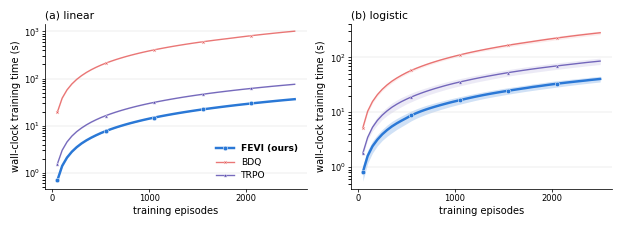

[linear] training seconds at the end (mean ± std over seeds):  FEVI=37±0  BDQ=1010±6  TRPO=76±1
[logistic] training seconds at the end (mean ± std over seeds):  FEVI=40±5  BDQ=281±21  TRPO=85±11


In [34]:
from matplotlib.ticker import MaxNLocator

PAPER_WIDTH = 5.5                      # ICLR \textwidth in inches
PAPER_RC = {"font.size": 6.5, "axes.labelsize": 6.5, "axes.titlesize": 7, "xtick.labelsize": 5.5,
            "ytick.labelsize": 5.5, "legend.fontsize": 6, "axes.linewidth": 0.5,
            "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2,
            "ytick.major.size": 2, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5,
            "axes.labelpad": 2, "grid.linewidth": 0.3, "pdf.fonttype": 42}
WC_LW = {"TRPO": 0.9, "BDQ": 0.9, OURS: 1.6}

with plt.rc_context(PAPER_RC):
    fig, axes = plt.subplots(1, len(SHOWN), figsize=(PAPER_WIDTH, 1.9), squeeze=False)
    for k, (ax, t) in enumerate(zip(axes[0], SHOWN)):
        for n in LEARNERS:
            H = np.array([lg[n]["time"] for lg in per_seed(t, "logs")])     # cumulative training seconds
            mu, sd = H.mean(0), H.std(0)
            x = np.arange(1, len(mu) + 1) * res[t]["episodes_per_update"]
            ours = n == OURS
            ax.plot(x, mu, "-", marker=MARKERS[n], color=COLORS[n], lw=WC_LW[n], ms=3.0 if ours else 2.2,
                    mec="white", mew=0.3, markevery=max(1, len(x) // 5), alpha=1.0 if ours else 0.75,
                    zorder=4 if ours else 3, label=f"{n} (ours)" if ours else n)
            ax.fill_between(x, mu - sd, mu + sd, color=COLORS[n], alpha=0.22 if ours else 0.1, lw=0)
        ax.set_yscale("log")
        ax.set_xticks([0, 1000, 2000])
        ax.set_xlabel("training episodes")
        ax.set_ylabel("wall-clock training time (s)")
        ax.set_title(f"({'abcdefgh'[k]}) {t}", loc="left", pad=3)
        ax.grid(True, axis="y", which="major")
    leg = axes[0, 0].legend(loc="lower right")
    for text in leg.get_texts():
        if text.get_text().endswith("(ours)"):
            text.set_fontweight("bold")
    fig.tight_layout(pad=0.2, w_pad=1.0)
    os.makedirs("figures", exist_ok=True)
    fig.savefig("figures/wallclock_vs_episodes.pdf", bbox_inches="tight")
    plt.show()

for t in SHOWN:
    print(f"[{t}] training seconds at the end (mean ± std over seeds):  "
          + "  ".join(f"{n}={np.mean([lg[n]['time'][-1] for lg in per_seed(t, 'logs')]):.0f}"
                      f"±{np.std([lg[n]['time'][-1] for lg in per_seed(t, 'logs')]):.0f}" for n in LEARNERS))
